## Random Walk
### Code and Output:

Starting Random Walk Simulator...
Simulating 1D Walk...


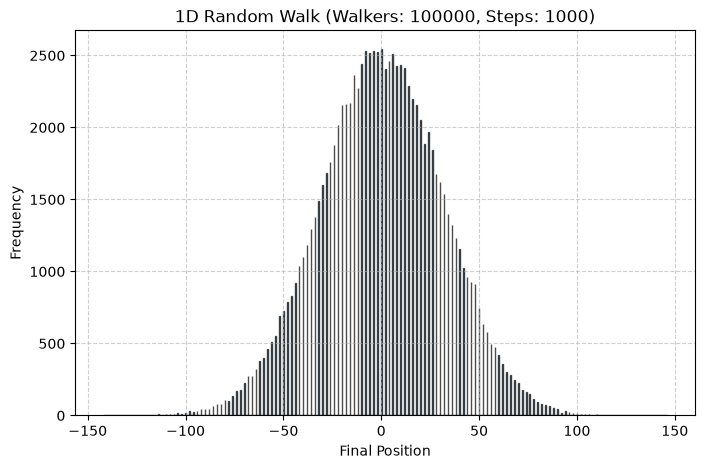

Simulating 2D Walk...


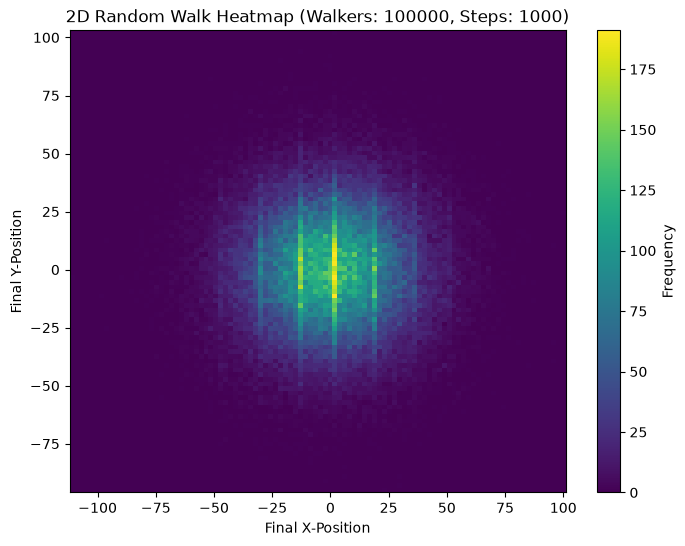

Simulating 3D Walk...


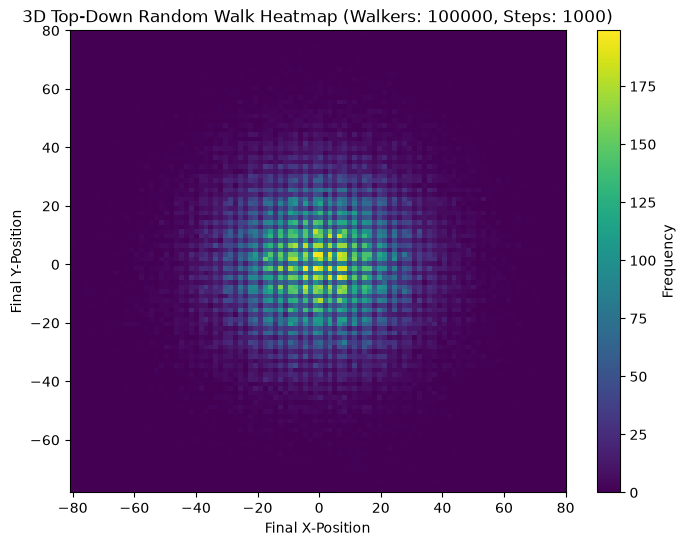

Plotting FWHM...


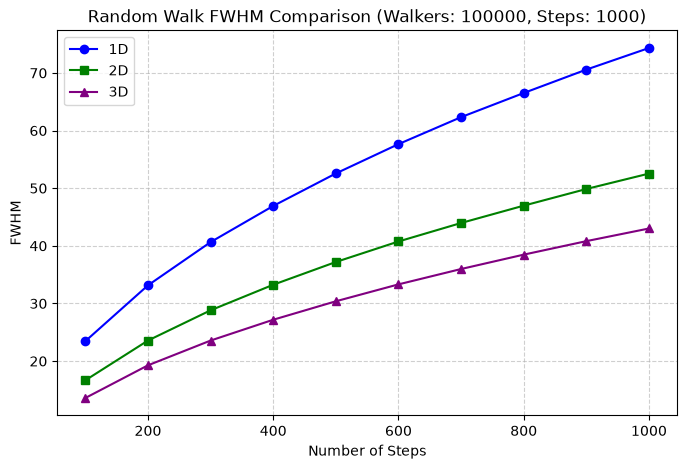

Plotting Origin-return distribution and calculating Slopes...
1D Slope: -0.516
2D Slope: -1.021
3D Slope: -1.539


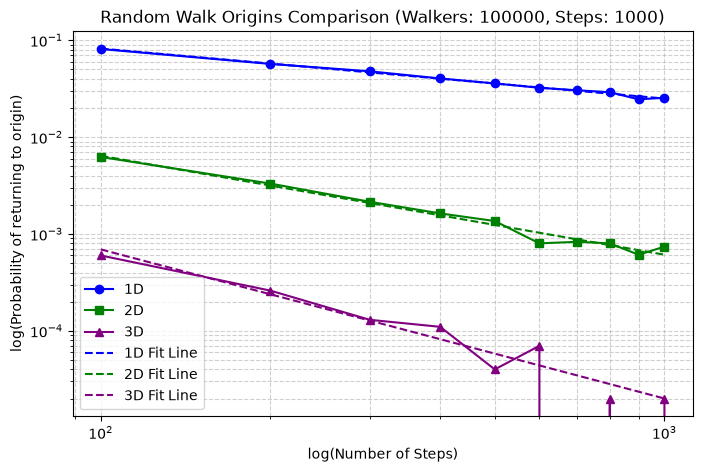

In [1]:
import matplotlib.pyplot as plt
import numpy as np


# ==========================================
# 1. VISUALIZATION FUNCTIONS
# ==========================================
def plot_heatmap(final_x, final_y, dimension_name):
    """Plots a 2D Heatmap."""
    plt.figure(figsize=(8, 6))
    plt.hist2d(final_x, final_y, bins=100, cmap="viridis")
    cbar = plt.colorbar()
    cbar.set_label("Frequency")
    plt.title(
        f"{dimension_name} Random Walk Heatmap (Walkers: {n_walkers}, Steps: {n_steps})"
    )
    plt.xlabel("Final X-Position")
    plt.ylabel("Final Y-Position")
    plt.show()


# ==========================================
# 2. SIMULATION FUNCTION
# ==========================================
def simulate_walk(choices, n_walkers, step_counts):
    """Simulates a random walk."""
    n_intervals = len(step_counts)
    fwhm = np.zeros(n_intervals)
    origin_prob = np.zeros(n_intervals)
    dimensions = len(choices[0])

    current_positions = np.zeros((n_walkers, dimensions))
    last_checkpoint = 0
    for i in range(n_intervals):
        current_checkpoint = step_counts[i]
        steps_to_take = current_checkpoint - last_checkpoint
        num_choices = len(choices)
        random_indices = np.random.choice(num_choices, size=(n_walkers, steps_to_take))
        steps = choices[random_indices]
        total_steps = np.sum(steps, axis=1)
        current_positions = current_positions + total_steps

        # FWHM
        std_dev = np.std(current_positions, axis=0)
        fwhm[i] = np.mean(2.355 * std_dev)

        # Origin Probability:
        distance_from_origin = np.sum(np.abs(current_positions), axis=1)
        walkers_at_origin = np.sum(distance_from_origin == 0)
        origin_prob[i] = walkers_at_origin / n_walkers

        last_checkpoint = current_checkpoint

    return fwhm, origin_prob, current_positions


# ==========================================
# 3. LINE FITTING FUNCTION
# ==========================================
def line_fit(step_counts, origin_probs):
    """Fits a line to the origin probabilities."""
    # Check for zero error
    valid_mask = origin_probs > 0
    valid_steps = step_counts[valid_mask]
    valid_probs = origin_probs[valid_mask]
    log_steps = np.log10(valid_steps)
    log_probs = np.log10(valid_probs)

    # Calculates slope and intercept and performs line fit
    slope, intercept = np.polyfit(log_steps, log_probs, 1)
    fit_line = (slope * np.log10(step_counts)) + intercept
    actual_fit = 10**fit_line

    return actual_fit, slope


# ==========================================
# 4. SETUP
# ==========================================
print("Starting Random Walk Simulator...")
n_walkers = int(input("Enter the number of walkers (e.g., 100000): "))
n_steps = int(input("Enter the number of steps (e.g., 1000): "))
step_counts = np.array(range(100, n_steps + 1, 100))

choices_1d = np.array([[-1], [1]])
choices_2d = np.array([[1, 0], [-1, 0], [0, 1], [0, -1]])
choices_3d = np.array(
    [[1, 0, 0], [-1, 0, 0], [0, 1, 0], [0, -1, 0], [0, 0, 1], [0, 0, -1]]
)


# ==========================================
# 5. FINAL POSITION HISTOGRAM
# ===========================================

# 1D
print("Simulating 1D Walk...")
fwhm_1d, prob_1d, final_1d = simulate_walk(choices_1d, n_walkers, step_counts)
plt.figure(figsize=(8, 5))
plt.hist(final_1d[:, 0], bins=1000, edgecolor="black", alpha=0.7)
plt.grid(True, linestyle="--", alpha=0.6)
plt.title(f"1D Random Walk (Walkers: {n_walkers}, Steps: {n_steps})")
plt.xlabel("Final Position")
plt.ylabel("Frequency")
plt.show()

# 2D
print("Simulating 2D Walk...")
fwhm_2d, prob_2d, final_2d = simulate_walk(choices_2d, n_walkers, step_counts)
plot_heatmap(final_2d[:, 0], final_2d[:, 1], "2D")

# 3D
print("Simulating 3D Walk...")
fwhm_3d, prob_3d, final_3d = simulate_walk(choices_3d, n_walkers, step_counts)
plot_heatmap(final_3d[:, 0], final_3d[:, 1], "3D Top-Down")


# ==========================================
# 6. FWHM-ORIGIN PLOTS & FITTING
# ==========================================

# FWHM Plot
print("Plotting FWHM...")
plt.figure(figsize=(8, 5))
plt.plot(step_counts, fwhm_1d, marker="o", color="blue", label="1D")
plt.plot(step_counts, fwhm_2d, marker="s", color="green", label="2D")
plt.plot(step_counts, fwhm_3d, marker="^", color="purple", label="3D")
plt.grid(True, linestyle="--", alpha=0.6)
plt.title(f"Random Walk FWHM Comparison (Walkers: {n_walkers}, Steps: {n_steps})")
plt.xlabel("Number of Steps")
plt.ylabel("FWHM")
plt.legend()
plt.show()

# Calculate the lines of best fit for Origin Plot
print("Plotting Origin-return distribution and calculating Slopes...")
fit_1d, slope_1d = line_fit(step_counts, prob_1d)
fit_2d, slope_2d = line_fit(step_counts, prob_2d)
fit_3d, slope_3d = line_fit(step_counts, prob_3d)

print(f"1D Slope: {slope_1d:.3f}")
print(f"2D Slope: {slope_2d:.3f}")
print(f"3D Slope: {slope_3d:.3f}")

# Origin-Return Plot
plt.figure(figsize=(8, 5))
plt.plot(step_counts, prob_1d, marker="o", color="blue", label="1D")
plt.plot(step_counts, prob_2d, marker="s", color="green", label="2D")
plt.plot(step_counts, prob_3d, marker="^", color="purple", label="3D")

plt.plot(step_counts, fit_1d, color="blue", linestyle="--", label="1D Fit Line")
plt.plot(step_counts, fit_2d, color="green", linestyle="--", label="2D Fit Line")
plt.plot(step_counts, fit_3d, color="purple", linestyle="--", label="3D Fit Line")

plt.xscale("log")
plt.yscale("log")
plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.title(f"Random Walk Origins Comparison (Walkers: {n_walkers}, Steps: {n_steps})")
plt.xlabel("log(Number of Steps)")
plt.ylabel("log(Probability of returning to origin)")
plt.legend()
plt.show()


### Algorithm:

1. Prompt user to input the total number of walkers and steps.
2. Generate an array of checkpoints spaced uniformly by increments of 100 from 100 up to number of steps using numpy array.
3. Define the discrete directional movement choices as NumPy arrays for the three spatial dimensions:
    1D: Move left [-1] or right [1].
    2D: Move right [1, 0], left [-1, 0], up [0, 1], or down [0, -1].
    3D: Move across six orthogonal Cartesian axes ([1, 0, 0], [-1, 0, 0], etc.).
4. Call simulate_walk() function for 1D, 2D and 3D, capturing the returned FWHM metrics, origin probabilities, and final positions for all the dimensions.
5. Plot a frequency histogram of the final positions for all the dimensions.
6. Plot the FWHM comaprison plot.
7. Pass the step checkpoints and origin probabilities into line_fit() for each dimension to compute their logarithmic trendlines and slopes.
8. Print the slopes.
9. Plot both the combined raw simulation scatter points and their respective dashed trendline fits of all dimensions with logarithmic scale.

### Functions:

#### 1. simulate_walk()
Takes choices, n_walkers, step_counts.
1. Calculate how many checkpoint intervals will be analyzed.
2. Pre-allocate zero-arrays to metrics.
3. Inspect the shape of the directional choices array to automatically detect whether the simulation is running in 1D, 2D, or 3D space.
4. Initialize a coordinate tracking matrix where every walker starts at the origin vector $(0, 0, \dots)$.
5. Set a tracker variable to measure incremental step batches.
6. Loop through each checkpoint interval.
7. Retrieve the current target step count.
8. Determine the size of the current batch.
9. Count how many movement options are available for the given dimension (e.g., 2 for 1D, 4 for 2D, 6 for 3D).
10. Generate a batch matrix of random integer indices representing movement choices for all walkers across the batch steps.
11. Map the random indices back to their actual vector coordinates.
12. Sum the step vectors across the batch axis to find the net displacement each walker achieved.
13. Update the cumulative global coordinates of the entire crowd.
14. Compute the standard deviation of walker positions across each spatial axis.
15. Convert standard deviation into Full Width at Half Maximum ($2.355 \sigma$) and average across axes to record the crowd's spatial spread at this checkpoint.
16. Calculate the distance of each walker from the center.
17. Count how many walkers are standing precisely at the coordinate center.
18. Compute the fraction of walkers at the origin, recording the return probability.
19. Update the checkpoint marker for the next iteration.
20. Output the completed metric arrays and the final coordinate matrix.


#### 2. line_fit()
Takes step_counts, origin_probs
1. Create a boolean mask array filtering out any zero-probability values where no walkers returned to the origin.
2. Extract only the non-zero steps and probabilities, preventing $\log_{10}(0) = -\infty$ crashes.
3. Convert the filtered datasets into base-10 logarithmic space.
4. Fit a first-degree linear polynomial to the log-log data to extract the slope and y-intercept.
5. Compute the linear trendline values across all original step counts in log space.
6. Exponentiate the trendline values back into standard linear scale coordinates for proper visualization.
7. Return the true-scale trendline array and the calculated slope.